# Phase B.2 - Decoder Fine-Tuning Experiment
Objective:

Evaluate whether adapting a small subset of decoder parameters improves agricultural parcel segmentation under the SA‑1B → Sentinel‑2 domain shift.

Trainable parameters:

* transformer.layers[1]
* iou_prediction_head

Total trainable:

* 1,712,132 parameters

* 3.72 % of the model

In [4]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.optim as optim

from PIL import Image

from google.colab import drive

# URL de repositorio
!git clone https://github.com/ZagonTM/Sen4Sam
# Una vez clonado, nos movemos al directorio del repositorio o lo añadimos al path
import os
if os.path.exists('Sen4Sam'):
    %cd Sen4Sam
    print("Acceso al repositorio Sen4Sam exitoso.")
else:
    print("No se pudo encontrar la carpeta del repositorio. Verifica la URL de clonación.")

# Instalar Segment Anything 2 (SAM 2) y sus dependencias
!pip install -q git+https://github.com/facebookresearch/sam2.git

# Crear directorio de checkpoints y descargar los pesos del modelo
!mkdir -p checkpoints
!wget -P checkpoints/ https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_small.pt

ROOT = Path.cwd()

DATA_ROOT = Path(
    "/content/drive/MyDrive/Sen4SAM"
)

PROCESSED = (
    DATA_ROOT /
    "processed" /
    "processed"
)

Cloning into 'Sen4Sam'...
remote: Enumerating objects: 149, done.
remote: Counting objects: 100% (149/149), done.
remote: Compressing objects: 100% (106/106), done.
remote: Total 149 (delta 66), reused 106 (delta 40), pack-reused 0 (from 0)
Receiving objects: 100% (149/149), 3.57 MiB | 13.99 MiB/s, done.
Resolving deltas: 100% (66/66), done.
/content/Sen4Sam/Sen4Sam/Sen4Sam
Acceso al repositorio Sen4Sam exitoso.
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
--2026-11-08 19:53:17--  https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_small.pt
Resolving dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)... 3.167.112.129,

In [ ]:
# Comprobar que Colab usa GPU (sin GPU el encoder tarda ~8 s por imagen en lugar de ~0.3 s).
# Si falla: Entorno de ejecucion > Cambiar tipo de entorno de ejecucion > T4 GPU, y volver a ejecutar desde el principio.
import torch

REQUIRE_GPU = True

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
elif REQUIRE_GPU:
    raise RuntimeError("No hay GPU activa. Activa una GPU en el tipo de entorno de ejecucion de Colab.")
else:
    print("AVISO: ejecutando sin GPU (muy lento).")

Configuracion

In [28]:
EPOCHS = 3

LR = 1e-4

TRAIN_SAMPLES = 10

Dataset

In [ ]:
def load_rgb(patch):

    return np.array(
        Image.open(
            DATA_ROOT / "processed"/ "processed" / f"{patch}_rgb.png"
        ).convert("RGB")
    )
def load_parcels(patch):

    return np.load(
        DATA_ROOT / "processed"/ "processed" / f"{patch}_parcels.npy"
    )

from google.colab import drive

drive.mount('/content/drive')

gt_dataset = pd.read_csv(
    DATA_ROOT / "gt_parcel_dataset.csv"
)

# Split train/val/test por PARCHE (results/split.csv, semilla 42, estratificado por tesela).
# Para entrenar solo se usan parches de "train"; "test" queda reservado para la evaluacion final.
SPLIT_PATH = next((p for p in [ROOT / "results" / "split.csv", DATA_ROOT / "split.csv"] if p.exists()), None)
assert SPLIT_PATH is not None, "No se encuentra split.csv (repositorio: results/split.csv, o Drive: Sen4SAM/split.csv)"
split = pd.read_csv(SPLIT_PATH)
split_of = dict(zip(split["patch"], split["split"]))
gt_dataset = gt_dataset[gt_dataset["patch"].map(split_of) == "train"]
print("split:", SPLIT_PATH, "| parcelas de train:", len(gt_dataset), "| parches de train:", gt_dataset["patch"].nunique())

train_df = gt_dataset.sample(
    TRAIN_SAMPLES,
    random_state=42
)

Optimizador

In [30]:
sys.path.insert(
    0,
    str(ROOT / "src")
)
from sam2_auto_segment import build_model

model = build_model()

# Congelar todo
for p in model.parameters():
    p.requires_grad = False

# Seleccionar componentes de la intervención
last_block = (
    model.sam_mask_decoder
    .transformer
    .layers[1]
)

iou_head = (
    model.sam_mask_decoder
    .iou_prediction_head
)

# Descongelar únicamente estas capas
for p in last_block.parameters():
    p.requires_grad = True

for p in iou_head.parameters():
    p.requires_grad = True

# Verificamos
trainable = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Trainable:", trainable)

#Predictor
from sam2.sam2_image_predictor import SAM2ImagePredictor
predictor = SAM2ImagePredictor(model)

#Optimizador
optimizer = torch.optim.Adam(
    filter(
        lambda p: p.requires_grad,
        model.parameters()
    ),
    lr=LR
)

Trainable: 1712132


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## Baseline: modelo sin entrenar sobre el conjunto de TEST

Antes de entrenar se evalua el modelo original con el generador automatico de mascaras
sobre los parches de **test** (`results/split.csv`). Mismos ajustes y mismas metricas que la
linea base de `src/evaluate_masks.py` (`points_per_side=16`, `pred_iou_thresh=0.5`,
`stability_score_thresh=0.8`). Despues del entrenamiento se repite esta evaluacion para comparar.


In [ ]:
import time
from evaluate_masks import evaluate_patch
from sam2_auto_segment import build_mask_generator

EVAL_LIMIT = None   # p.ej. 10 para una prueba rapida; None = todos los parches de test

test_patches = split.loc[split["split"] == "test", ["country", "tile", "patch"]]
if EVAL_LIMIT:
    test_patches = test_patches.head(EVAL_LIMIT)


def evaluate_model_on_patches(model, patches_df):
    generator = build_mask_generator(
        model, points_per_side=16, pred_iou_thresh=0.5, stability_score_thresh=0.8
    )
    rows = []
    t0 = time.time()
    for i, r in enumerate(patches_df.itertuples(index=False), 1):
        metrics = evaluate_patch(load_rgb(r.patch), load_parcels(r.patch), generator)
        rows.append({"country": r.country, "tile": r.tile, "patch": r.patch, **metrics})
        if i % 20 == 0 or i == len(patches_df):
            print(f"[{i}/{len(patches_df)}] {time.time() - t0:.0f}s")
    return pd.DataFrame(rows)


SUMMARY_COLS = ["mean_best_iou", "median_best_iou", "frac_iou_gt_0.5", "mask_on_field_fraction", "n_masks"]


def summarize_eval(df, title):
    print(f"\n=== {title} ({len(df)} parches) ===")
    print(df[SUMMARY_COLS].mean().round(4).to_string())
    print()
    print(df.groupby("country")[SUMMARY_COLS].mean().round(4).to_string())


baseline_test = evaluate_model_on_patches(model, test_patches)
baseline_test.to_csv(DATA_ROOT / "eval_test_untrained.csv", index=False)
summarize_eval(baseline_test, "Modelo sin entrenar - TEST")

In [ ]:
# Control: los mismos parches ya estan en results/eval_patches.csv (linea base de los 888 parches).
# Las diferencias deben ser ~0 (solo ruido numerico del dispositivo).
ref_path = ROOT / "results" / "eval_patches.csv"
if ref_path.exists():
    ref = pd.read_csv(ref_path).set_index("patch").loc[baseline_test["patch"]]
    diff = (baseline_test.set_index("patch")["mean_best_iou"] - ref["mean_best_iou"]).abs()
    print("mean_best_iou aqui     :", round(baseline_test["mean_best_iou"].mean(), 4))
    print("mean_best_iou en el CSV:", round(ref["mean_best_iou"].mean(), 4))
    print("diferencia absoluta max por parche:", round(diff.max(), 4))
else:
    print("results/eval_patches.csv no encontrado; se omite el control.")

Bucle de entrenamiento

In [31]:
print("TRAIN_SAMPLES =", TRAIN_SAMPLES)

print("Filas de train_df =", len(train_df))

TRAIN_SAMPLES = 10
Filas de train_df = 10


In [32]:

import torch.nn.functional as F

def load_parcel_mask(
    patch,
    parcel_id
):

    parcels = np.load(
        PROCESSED /
        f"{patch}_parcels.npy"
    )

    return (
        parcels == parcel_id
    ).astype(np.float32)

def dice_loss(
    pred,
    target,
    eps=1e-6
):

    pred = pred.reshape(-1)

    target = target.reshape(-1)

    inter = (
        pred * target
    ).sum()

    dice = (
        2 * inter + eps
    ) / (
        pred.sum()
        + target.sum()
        + eps
    )

    return 1 - dice

import time

feature_cache = {}

epoch_losses = []

for epoch in range(EPOCHS):

    running_loss = 0

    print(
        f"\n========== Epoch {epoch+1}/{EPOCHS} =========="
    )

    for local_idx, (_, row) in enumerate(
        train_df.iterrows()
    ):

        patch = row["patch"]

        # -----------------------------------
        # CACHE DEL ENCODER
        # -----------------------------------

        if patch not in feature_cache:

            image = load_rgb(patch)

            start_encoder = time.time()

            predictor.set_image(image)

            encoder_time = (
                time.time()
                - start_encoder
            )

            print(
                f"[ENCODER] {patch} "
                f"{encoder_time:.2f}s"
            )

            feature_cache[patch] = {

                "image_embed":
                    predictor._features[
                        "image_embed"
                    ],

                "high_res_feats":
                    predictor._features[
                        "high_res_feats"
                    ]
            }

        image_embed = (
            feature_cache[patch]
            ["image_embed"]
        )

        high_res_feats = (
            feature_cache[patch]
            ["high_res_feats"]
        )

        # -----------------------------------
        # POSITIONAL ENCODING
        # -----------------------------------

        image_pe = (
            model.sam_prompt_encoder
            .get_dense_pe()
        )

        # -----------------------------------
        # PROMPT
        # -----------------------------------

        # Las parcelas estan en pixeles del parche (366x366); SAM espera coordenadas en su marco de 1024x1024.
        # transform_coords normaliza por (alto, ancho) y escala a 1024 (igual que predictor.predict).
        point_coords = predictor._transforms.transform_coords(
            torch.tensor([[[row["cx"], row["cy"]]]], dtype=torch.float32,
                         device=image_embed.device),
            normalize=True,
            orig_hw=(366, 366)
        )

        point_labels = torch.tensor(
            [[1]],
            dtype=torch.int64,
            device=image_embed.device
        )

        sparse_embeddings, dense_embeddings = (
            model.sam_prompt_encoder(
                points=(
                    point_coords,
                    point_labels
                ),
                boxes=None,
                masks=None
            )
        )

        # -----------------------------------
        # DECODER
        # -----------------------------------

        masks, iou_pred, mask_tokens, obj_logits = (
            model.sam_mask_decoder.predict_masks(

                image_embeddings=image_embed,

                image_pe=image_pe,

                sparse_prompt_embeddings=sparse_embeddings,

                dense_prompt_embeddings=dense_embeddings,

                repeat_image=False,

                high_res_features=high_res_feats
            )
        )

        # -----------------------------------
        # GT
        # -----------------------------------

        gt_mask = load_parcel_mask(
            patch,
            row["parcel_id"]
        )

        gt_mask = torch.tensor(
            gt_mask,
            dtype=torch.float32,
            device=image_embed.device
        )

        gt_mask = (
            gt_mask
            .unsqueeze(0)
            .unsqueeze(0)
        )

        gt_mask = F.interpolate(
            gt_mask,
            size=(
                masks.shape[-2],
                masks.shape[-1]
            ),
            mode="nearest"
        )

        # -----------------------------------
        # LOSS
        # -----------------------------------

        pred_probs = torch.sigmoid(
            masks[:, 0:1]
        )

        loss = dice_loss(
            pred_probs,
            gt_mask
        )

        optimizer.zero_grad()

        loss.backward()

        # -----------------------------------
        # VERIFICAR GRADIENTES
        # -----------------------------------

        if (
            epoch == 0
            and local_idx == 0
        ):

            grad = next(
                last_block.parameters()
            ).grad

            print(
                "Gradient norm:",
                grad.norm().item()
            )

        optimizer.step()

        running_loss += loss.item()

        print(
            f"[{local_idx+1}/{len(train_df)}] "
            f"Loss={loss.item():.4f}"
        )

    mean_loss = (
        running_loss
        / len(train_df)
    )

    epoch_losses.append(
        mean_loss
    )

    print(
        f"Epoch {epoch+1} "
        f"Mean Loss = {mean_loss:.4f}"
    )


========== Epoch 1/3 ==========
[ENCODER] 2019_31TBF_patch_24_24 7.44s
Gradient norm: 0.0006851739599369466
[1/10] Loss=0.9975
[2/10] Loss=0.9991
[ENCODER] 2019_31TDG_patch_26_08 9.57s
[3/10] Loss=0.9996
[ENCODER] 2019_31TBF_patch_25_00 7.64s
[4/10] Loss=0.9993
[ENCODER] 2019_31TBF_patch_19_13 9.11s
[5/10] Loss=0.9982
[ENCODER] 2019_31TDK_patch_16_14 9.00s
[6/10] Loss=0.9984
[ENCODER] 2019_31TDG_patch_09_23 7.76s
[7/10] Loss=0.9995
[ENCODER] 2019_31TBF_patch_23_23 9.65s
[8/10] Loss=0.9883
[ENCODER] 2019_31TCL_patch_13_27 7.57s
[9/10] Loss=0.9988
[ENCODER] 2019_31TCL_patch_17_14 9.44s
[10/10] Loss=0.9990
Epoch 1 Mean Loss = 0.9978

========== Epoch 2/3 ==========
[1/10] Loss=0.9970
[2/10] Loss=0.9969
[3/10] Loss=0.9992
[4/10] Loss=0.9991
[5/10] Loss=0.9977
[6/10] Loss=0.9983
[7/10] Loss=0.9994
[8/10] Loss=0.9831
[9/10] Loss=0.9979
[10/10] Loss=0.9982
Epoch 2 Mean Loss = 0.9967

========== Epoch 3/3 ==========
[1/10] Loss=0.9928
[2/10] Loss=0.9942
[3/10] Loss=0.9994
[4/10] Loss=0.9979
[

Curva entrenamiento

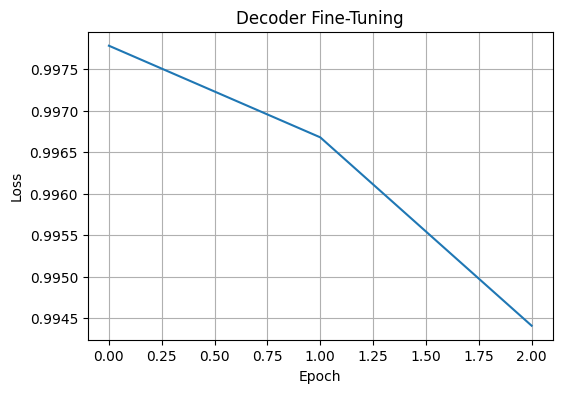

In [33]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6,4))

plt.plot(epoch_losses)

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title(
    "Decoder Fine-Tuning"
)

plt.grid(True)

plt.show()

Guardar checkpoint

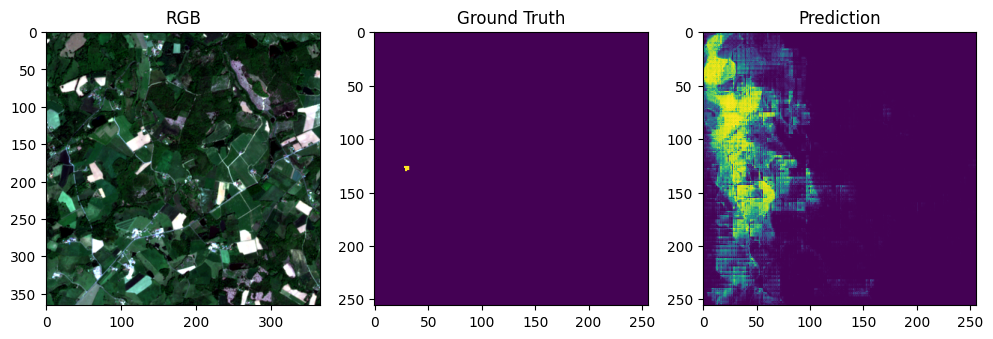

In [36]:
plt.figure(figsize=(12,4))

plt.subplot(131)
plt.imshow(image)
plt.title("RGB")

plt.subplot(132)
plt.imshow(gt_mask[0,0].cpu())
plt.title("Ground Truth")

plt.subplot(133)
plt.imshow(pred_probs[0,0].detach().cpu())
plt.title("Prediction")

plt.show()

In [35]:
torch.save(

    model.state_dict(),

    DATA_ROOT /
    "sam2_decoder_finetuned.pt"
)

## Resultados preliminares

Se implementó satisfactoriamente un pipeline de fine-tuning para SAM2 basado en supervisión parcelaria directa. Los gradientes alcanzaron los módulos seleccionados para adaptación (último bloque del Two-Way Transformer e IoU Prediction Head), confirmando que la intervención es funcional. Durante las primeras tres épocas se observó una reducción consistente de la Dice Loss media de 0.9978 a 0.9944, indicando capacidad de aprendizaje aunque con una magnitud todavía limitada.